# Peturb-seq:

In [1]:
import scanpy as sc
import requests
from pathlib import Path

url = "https://zenodo.org/records/7041849/files/AdamsonWeissman2016_GSM2406677_10X005.h5ad?download=1"
file_path = Path("AdamsonWeissman2016_GSM2406677_10X005.h5ad")

if not file_path.exists():
    with requests.get(url, stream=True, timeout=120) as response:
        response.raise_for_status()
        with open(file_path, "wb") as f:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk)

adata = sc.read_h5ad(file_path)

print(adata)
print(adata.obs.columns.tolist())
print(adata.var_names[:10].tolist())

AnnData object with n_obs × n_vars = 15006 × 32738
    obs: 'perturbation', 'read count', 'UMI count', 'tissue_type', 'cell_line', 'cancer', 'disease', 'perturbation_type', 'celltype', 'organism', 'ncounts', 'ngenes', 'percent_mito', 'percent_ribo', 'nperts'
    var: 'ensembl_id', 'ncounts', 'ncells'
['perturbation', 'read count', 'UMI count', 'tissue_type', 'cell_line', 'cancer', 'disease', 'perturbation_type', 'celltype', 'organism', 'ncounts', 'ngenes', 'percent_mito', 'percent_ribo', 'nperts']
['MIR1302-10', 'FAM138A', 'OR4F5', 'RP11-34P13.7', 'RP11-34P13.8', 'AL627309.1', 'RP11-34P13.14', 'RP11-34P13.9', 'AP006222.2', 'RP4-669L17.10']


In [2]:
adata.obs['perturbation'].value_counts()

perturbation
3x_neg_ctrl_pMJ144-1     1715
ATF6_PERK_IRE1_pMJ158    1693
ATF6_only_pMJ145         1691
IRE1_only_pMJ148         1685
3x_neg_ctrl_pMJ144-2     1650
PERK_IRE1_pMJ154         1629
ATF6_PERK_pMJ150         1603
PERK_only_pMJ146         1560
ATF6_IRE1_pMJ152         1449
*                          13
PSMD12_pDS009               6
PSMA1_pDS007                4
IER3IP1_pDS003              3
XBP1_pBA578                 2
C7orf26_pDS004              2
ATF4_pBA576                 1
Gal4-4(mod)_pBA582          1
SNAI1_pDS266                1
XBP1_pBA579                 1
YIPF5_pDS001                1
Name: count, dtype: int64

In [3]:
adata = adata[adata.obs['perturbation'].isin([
    '3x_neg_ctrl_pMJ144-1',
    'ATF6_only_pMJ145'
])].copy()

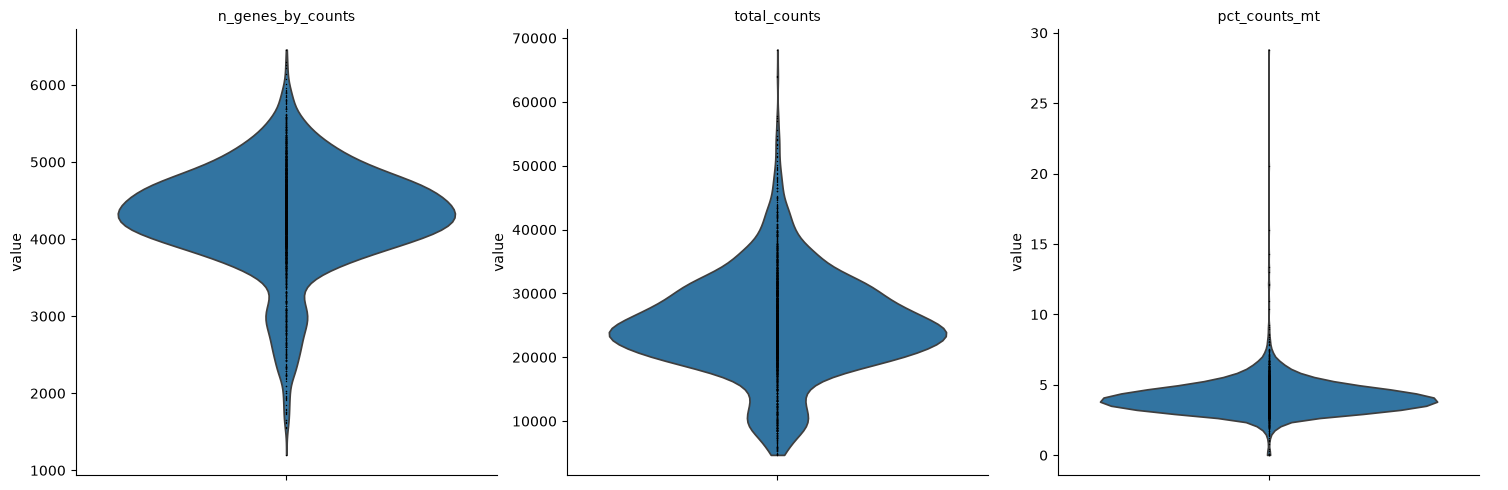

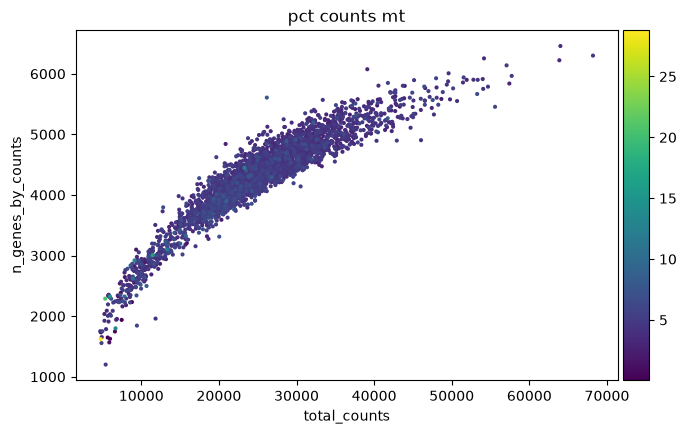

In [4]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))
adata.var["hb"] = adata.var_names.str.startswith(("HBA", "HBB"))

sc.pp.calculate_qc_metrics(
    adata, qc_vars=["mt", "ribo", "hb"], inplace=True, log1p=True)

sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.0,
    multi_panel=True)

sc.pl.scatter(adata, "total_counts", "n_genes_by_counts", color="pct_counts_mt")

In [5]:
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)

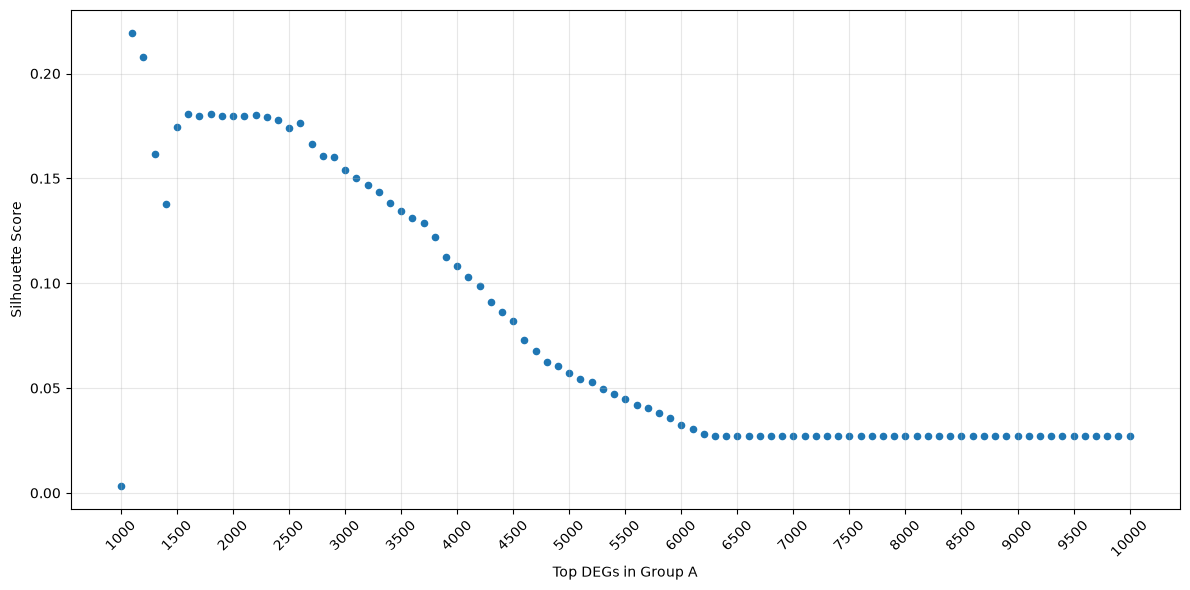

In [6]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

group_col = 'perturbation'
groups = adata.obs[group_col].dropna().unique()[:2].tolist()
adata_sub = adata[adata.obs[group_col].isin(groups)].copy()

sc.tl.rank_genes_groups(
    adata_sub,
    groupby=group_col,
    groups=[groups[0]],
    reference='rest',
    method='wilcoxon',
    use_raw=False
)

deg_A = sc.get.rank_genes_groups_df(adata_sub, group=groups[0])
scores = []

for n in range(1000, 10001, 100):
    top_A = deg_A.sort_values('logfoldchanges', ascending=False).head(n)
    selected_genes = [g for g in top_A['names'] if g in adata_sub.var_names]

    X = adata_sub[:, selected_genes].X
    if hasattr(X, 'toarray'):
        X = X.toarray()

    X_pca = PCA(n_components=2).fit_transform(X)
    score = silhouette_score(X_pca, adata_sub.obs[group_col])

    scores.append({'top_n': n, 'n_genes': len(selected_genes), 'silhouette_score': score})

scores_df = pd.DataFrame(scores)

plt.figure(figsize=(12, 6))
plt.scatter(scores_df['top_n'], scores_df['silhouette_score'], s=20)
plt.xlabel('Top DEGs in Group A')
plt.ylabel('Silhouette Score')
plt.xticks(np.arange(1000, 10001, 500), rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

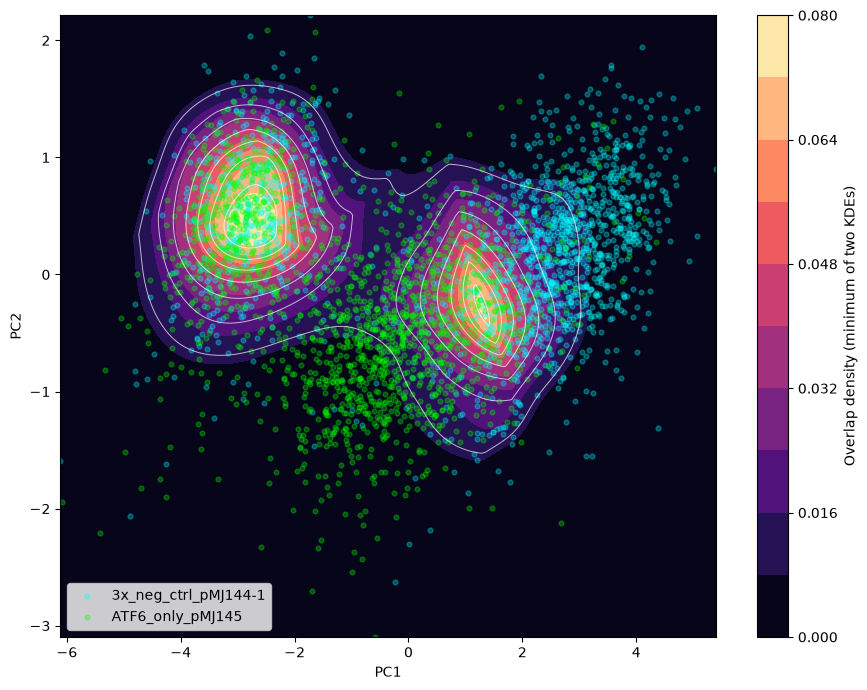

Group A: 3x_neg_ctrl_pMJ144-1, selected genes: 2600
Group B: ATF6_only_pMJ145


In [7]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from scipy.stats import gaussian_kde

group_col = 'perturbation'
groups = adata.obs[group_col].dropna().unique()[:2].tolist()

adata_sub = adata[adata.obs[group_col].isin(groups)].copy()

sc.tl.rank_genes_groups(
    adata_sub,
    groupby=group_col,
    groups=[groups[0]],
    reference='rest',
    method='wilcoxon',
    use_raw=False
)

deg_A = sc.get.rank_genes_groups_df(adata_sub, group=groups[0])
top_A = deg_A.sort_values('logfoldchanges', ascending=False).head(2600)

selected_genes = [g for g in top_A['names'] if g in adata_sub.var_names]

adata_pca = adata_sub[:, selected_genes].copy()

X = adata_pca.X
if hasattr(X, 'toarray'):
    X = X.toarray()

X_pca = PCA(n_components=2).fit_transform(X)

pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'], index=adata_pca.obs_names)
pca_df[group_col] = adata_pca.obs[group_col].values

fig, ax = plt.subplots(figsize=(9, 7))

x_min, x_max = pca_df['PC1'].min(), pca_df['PC1'].max()
y_min, y_max = pca_df['PC2'].min(), pca_df['PC2'].max()

xx, yy = np.mgrid[
    x_min:x_max:200j,
    y_min:y_max:200j
]

grid = np.vstack([xx.ravel(), yy.ravel()])
densities = []

for group in groups:
    subset = pca_df[pca_df[group_col] == group][['PC1', 'PC2']].values
    kde = gaussian_kde(subset.T)
    densities.append(kde(grid).reshape(xx.shape))

overlap_density = np.minimum(densities[0], densities[1])

ax.contourf(
    xx, yy, overlap_density,
    levels=12,
    cmap='magma'
)

ax.contour(
    xx, yy, overlap_density,
    levels=8,
    colors='white',
    linewidths=0.7,
    alpha=0.7
)

for group, color in zip(groups, ['cyan', 'lime']):
    subset = pca_df[pca_df[group_col] == group]
    ax.scatter(
        subset['PC1'],
        subset['PC2'],
        color=color,
        label=group,
        s=12,
        alpha=0.3
    )

plt.colorbar(
    ax.collections[0],
    ax=ax,
    label='Overlap density (minimum of two KDEs)'
)

ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.legend()
plt.tight_layout()
plt.show()

print(f'Group A: {groups[0]}, selected genes: {len(selected_genes)}')
print(f'Group B: {groups[1]}')

In [8]:
X_pca = PCA(n_components=2).fit_transform(X)

adata_pca.obsm['X_pca'] = X_pca

Cells before filtering: 3,406
Cells after filtering: 1,964
Removed cells: 1,442
Retained clusters: 10


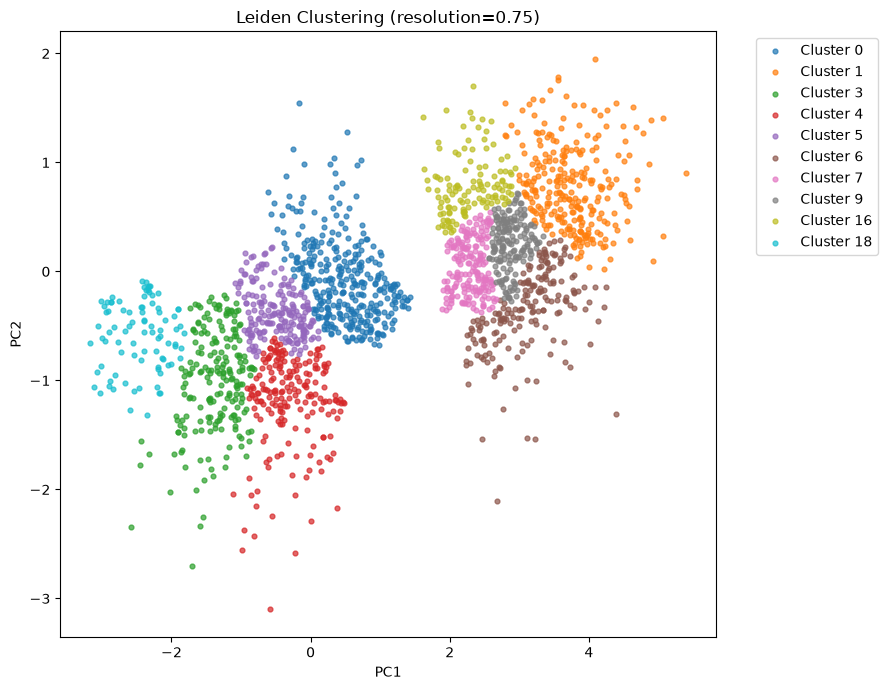

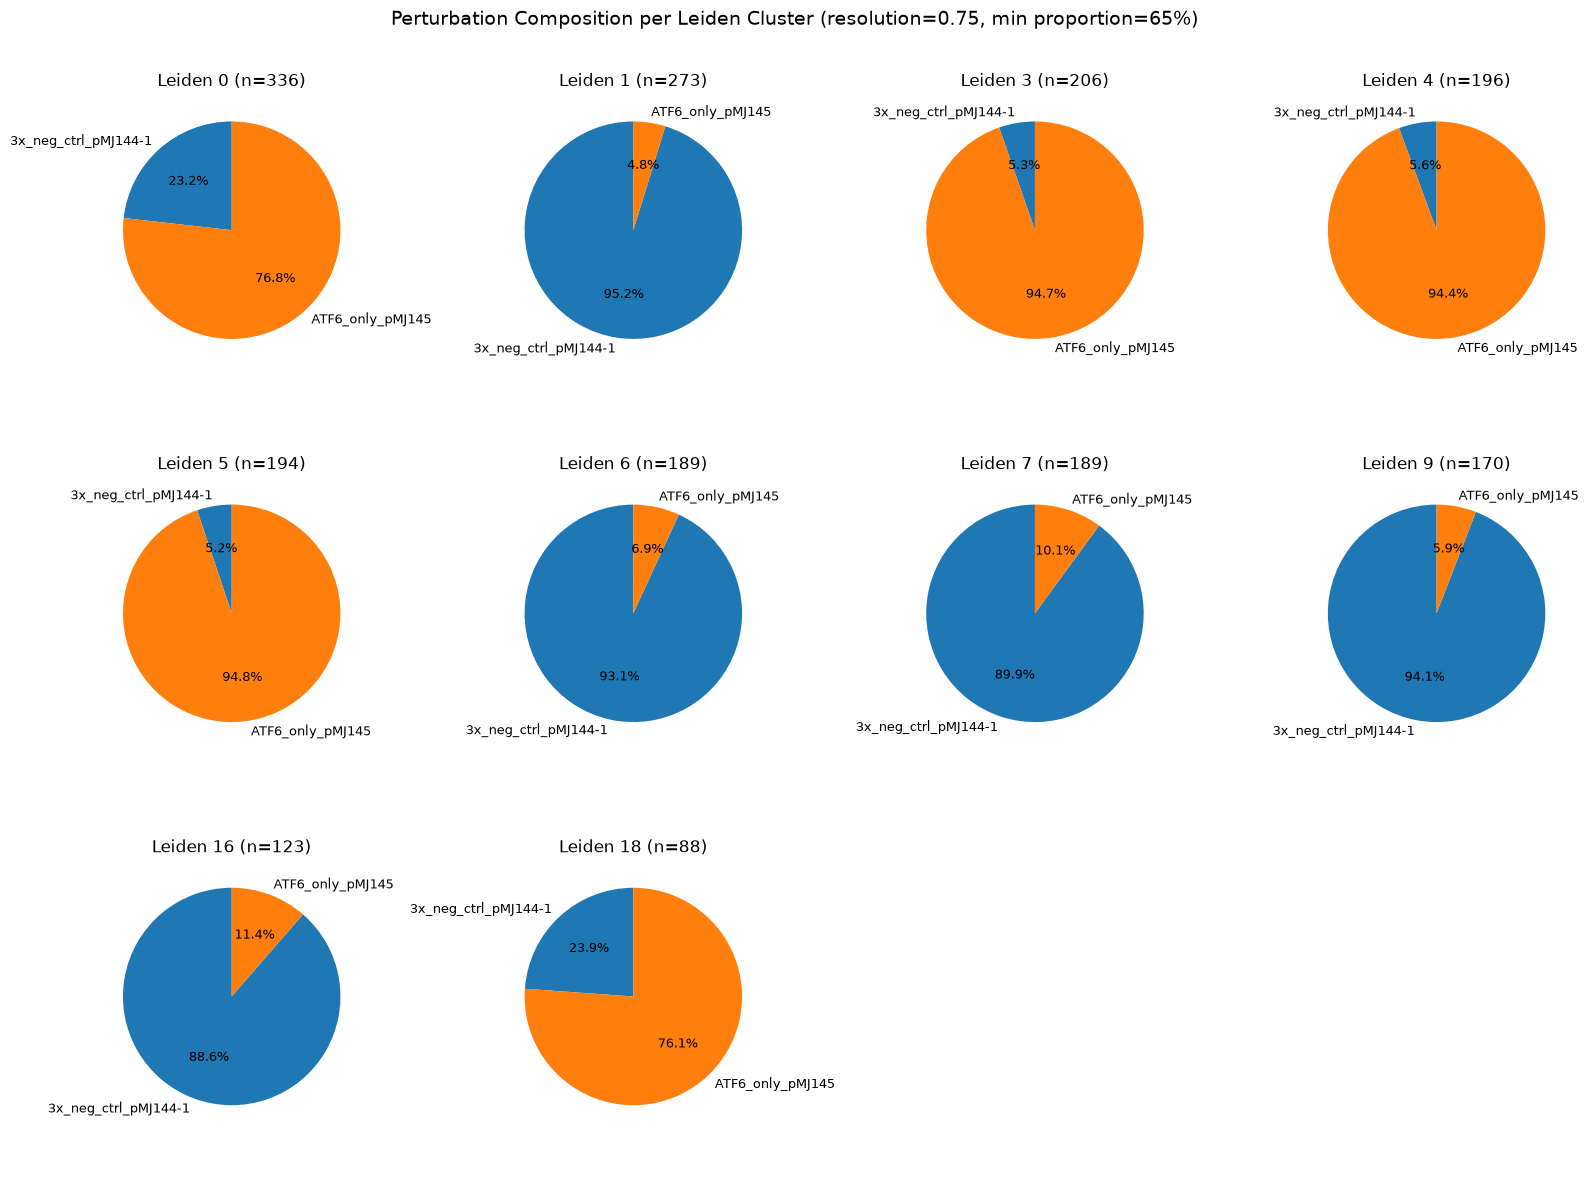

In [15]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math

group_col = 'perturbation'
resolution = 0.75
n_neighbors = 25
min_population_ratio = 0.65

sc.pp.neighbors(
    adata_pca,
    use_rep='X_pca',
    n_neighbors=n_neighbors
)

sc.tl.leiden(
    adata_pca,
    resolution=resolution,
    key_added='leiden_cluster'
)

cluster_counts = pd.crosstab(
    adata_pca.obs['leiden_cluster'],
    adata_pca.obs[group_col]
)

cluster_ratios = cluster_counts.div(
    cluster_counts.sum(axis=1),
    axis=0
)

valid_clusters = cluster_ratios.index[
    cluster_ratios.max(axis=1) >= min_population_ratio
]

n_cells_before = adata_pca.n_obs
adata_pca = adata_pca[
    adata_pca.obs['leiden_cluster'].isin(valid_clusters)
].copy()

print(f'Cells before filtering: {n_cells_before:,}')
print(f'Cells after filtering: {adata_pca.n_obs:,}')
print(f'Removed cells: {n_cells_before - adata_pca.n_obs:,}')
print(f'Retained clusters: {adata_pca.obs["leiden_cluster"].nunique()}')

X_pca = adata_pca.obsm['X_pca']
clusters = adata_pca.obs['leiden_cluster'].astype(str)

fig, ax = plt.subplots(figsize=(9, 7))

for cluster in sorted(clusters.unique(), key=int):
    mask = clusters.values == cluster

    ax.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=f'Cluster {cluster}',
        s=12,
        alpha=0.7
    )

ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_title(f'Leiden Clustering (resolution={resolution})')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

cluster_counts = pd.crosstab(
    adata_pca.obs['leiden_cluster'],
    adata_pca.obs[group_col]
)

cluster_ratios = cluster_counts.div(
    cluster_counts.sum(axis=1),
    axis=0
) * 100

cluster_summary = pd.DataFrame(index=cluster_counts.index)
cluster_summary['Total'] = cluster_counts.sum(axis=1)

for group in cluster_counts.columns:
    cluster_summary[f'{group}_n'] = cluster_counts[group]
    cluster_summary[f'{group}_%'] = cluster_ratios[group].round(2)

cluster_summary = cluster_summary.sort_index(
    key=lambda x: x.astype(int)
)

n_clusters = len(cluster_counts)
ncols = 4
nrows = max(1, math.ceil(n_clusters / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(4 * ncols, 4 * nrows)
)

axes = np.array(axes).reshape(-1)

for i, cluster in enumerate(cluster_counts.index):
    counts = cluster_counts.loc[cluster]
    counts = counts[counts > 0]

    axes[i].pie(
        counts.values,
        labels=counts.index,
        autopct='%1.1f%%',
        startangle=90,
        textprops={'fontsize': 9}
    )

    axes[i].set_title(
        f'Leiden {cluster} (n={int(counts.sum())})'
    )

for i in range(n_clusters, len(axes)):
    axes[i].axis('off')

plt.suptitle(
    f'Perturbation Composition per Leiden Cluster '
    f'(resolution={resolution}, min proportion={min_population_ratio:.0%})',
    fontsize=14
)

plt.tight_layout()
plt.show()

In [16]:
adata_pca.X = adata_pca.layers['counts'].copy()
adata_pca.X.max()

np.float32(556.0)

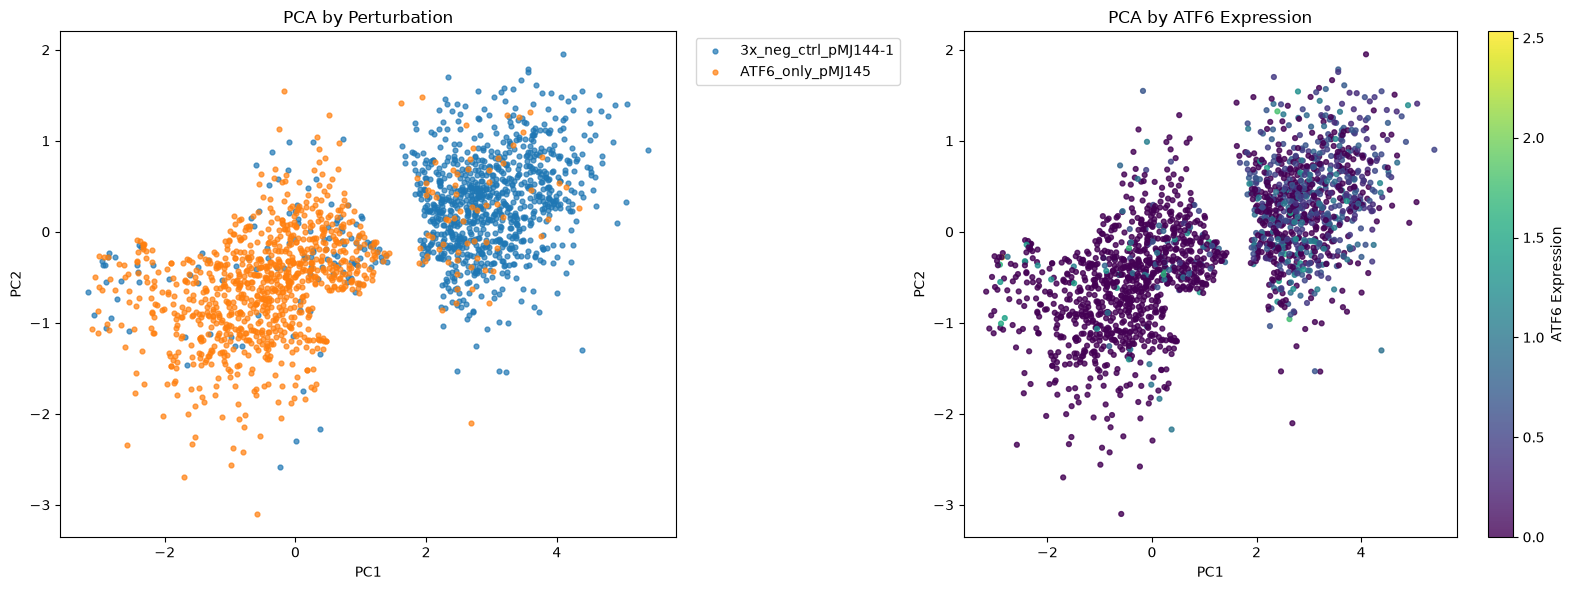

In [17]:
import numpy as np
import matplotlib.pyplot as plt

adata_pca.layers["counts"] = adata_pca.X.copy()
sc.pp.normalize_total(adata_pca)
sc.pp.log1p(adata_pca)

X_pca = adata_pca.obsm['X_pca']
groups = adata_pca.obs['perturbation'].astype(str)
atf6 = np.asarray(adata_pca[:, 'ATF6'].X.toarray()).flatten() if hasattr(adata_pca[:, 'ATF6'].X, 'toarray') else np.asarray(adata_pca[:, 'ATF6'].X).flatten()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for group in sorted(groups.unique()):
    mask = groups.values == group
    axes[0].scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=group,
        s=12,
        alpha=0.7
    )

sc1 = axes[1].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=atf6,
    cmap='viridis',
    s=12,
    alpha=0.8
)

axes[0].set_title('PCA by Perturbation')
axes[1].set_title('PCA by ATF6 Expression')

for ax in axes:
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')

axes[0].legend(bbox_to_anchor=(1.02, 1), loc='upper left')
fig.colorbar(sc1, ax=axes[1], label='ATF6 Expression')

plt.tight_layout()
plt.show()

adata_pca.X = adata_pca.layers["counts"].copy()

In [18]:
adata_pca.write_h5ad('/home/Data_Drive_8TB/kykim/8. RL/perturb-seq.h5ad')